# 01 · Cobertura del mapeo afiliación → país

Este notebook mide **qué tan confiable es la asignación de país**. Es la validación de la que
dependen todas las cifras posteriores: si una afiliación se asigna al país equivocado, todas las
métricas heredan el error.

La métrica que valida el estudio es **qué proporción de las publicaciones traídas por la búsqueda
tiene al menos un autor de la región**. Si baja de 100%, la query está trayendo cosas que no
corresponden.

El porcentaje de afiliaciones resueltas sobre el total **no** es una medida útil: la mayoría de las
afiliaciones de un paper son de coautores internacionales y nunca van a resolverse a un país del
estudio.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from astroca.config import get_loader
from astroca.storage import DataStore
from astroca import viz

viz.aplicar_estilo()

loader = get_loader()
store = DataStore(loader.settings().data_dir)

pubs = store.read_latest_raw("publications")
aff = store.read_latest_processed("author_affiliations")

print(f"publicaciones: {len(pubs)}   filas autor-afiliacion: {len(aff)}")
print(f"extraccion:    {store.extraction_date(store.latest_raw_path('publications'))}")

publicaciones: 273   filas autor-afiliacion: 1233
extraccion:    2026-10-23


## Validación principal: ¿toda publicación tiene un autor de la región?

In [2]:
total_pubs = pubs["bibcode"].nunique()
con_region = aff.loc[aff["iso3"].notna(), "bibcode"].nunique()

print(f"publicaciones con >=1 autor de la region: {con_region}/{total_pubs} "
      f"({con_region / total_pubs:.1%})")

sin_region = set(pubs["bibcode"]) - set(aff.loc[aff["iso3"].notna(), "bibcode"])
if sin_region:
    print(f"\nREVISAR — {len(sin_region)} publicaciones sin ningun autor de la region:")
    display(pubs[pubs["bibcode"].isin(sin_region)][["bibcode", "year", "title"]].head(20))
else:
    print("\nNinguna publicacion quedo sin autor de la region.")

publicaciones con >=1 autor de la region: 273/273 (100.0%)

Ninguna publicacion quedo sin autor de la region.


## Clasificación de las afiliaciones

In [3]:
con_afiliacion = aff[aff["aff"].notna() & (aff["aff"] != "-")]

region = con_afiliacion["iso3"].notna()
extranjeras = (~region) & con_afiliacion["is_foreign"]
sin_clasificar = (~region) & (~con_afiliacion["is_foreign"])

clasificacion = pd.Series({
    "De la región": int(region.sum()),
    "Coautor extranjero": int(extranjeras.sum()),
    "Sin clasificar": int(sin_clasificar.sum()),
})

print(clasificacion.to_string())
print(f"\ntotal con afiliacion: {len(con_afiliacion)}")
print(f"sin clasificar: {sin_clasificar.sum() / len(con_afiliacion):.1%} del total")

De la región          412
Coautor extranjero    746
Sin clasificar         68

total con afiliacion: 1226
sin clasificar: 5.5% del total


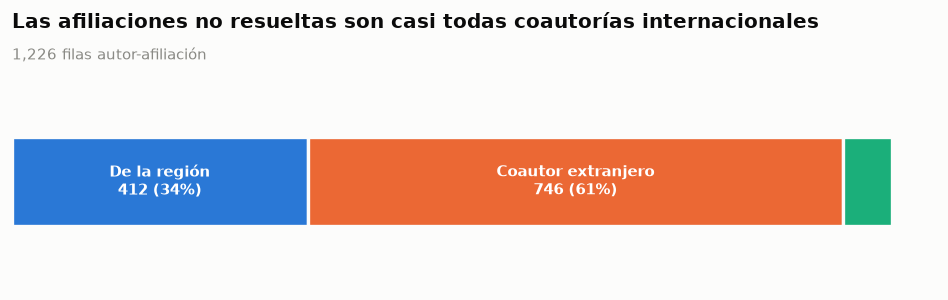

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.6))

izquierda = 0
colores = [viz.SERIE_1, viz.SERIE_2, viz.SERIE_3]
for (etiqueta, valor), color in zip(clasificacion.items(), colores):
    ax.barh([0], [valor], left=izquierda, color=color, height=0.5,
            edgecolor=viz.SUPERFICIE, linewidth=2)
    if valor / clasificacion.sum() > 0.06:
        ax.annotate(f"{etiqueta}\n{valor:,} ({valor / clasificacion.sum():.0%})",
                    (izquierda + valor / 2, 0), ha="center", va="center",
                    fontsize=9, color="white", fontweight="bold")
    izquierda += valor

ax.set_ylim(-0.6, 0.6)
ax.set_yticks([])
ax.grid(visible=False)
viz.limpiar_ejes(ax, ("top", "right", "left", "bottom"))
ax.set_xticks([])
viz.titulo(ax, "Las afiliaciones no resueltas son casi todas coautorías internacionales",
           f"{len(con_afiliacion):,} filas autor-afiliación")
plt.tight_layout()
plt.show()

## Por qué estrategia se resolvió cada afiliación

La cascada va de mayor a menor confianza. Si el grueso se resuelve por `city` o `email_tld` —las
dos menos confiables— conviene revisar la muestra a mano antes de confiar en las cifras.

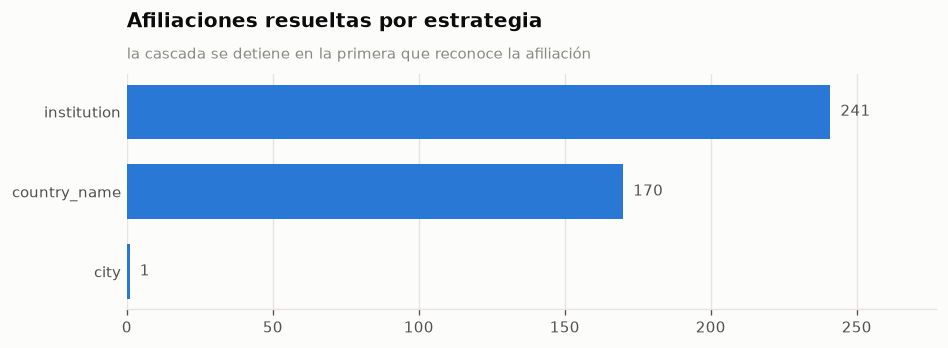

,filas,confianza,% del total resuelto
resolution_strategy,,,
institution,241,0.95,58.5
country_name,170,0.90,41.3
city,1,0.70,0.2


In [5]:
estrategias = aff["resolution_strategy"].value_counts()
confianzas = {"aff_id": 0.99, "institution": 0.95, "country_name": 0.90,
              "city": 0.70, "email_tld": 0.60}

fig, ax = plt.subplots(figsize=(8, 3))
viz.barras_horizontales(ax, estrategias.index.tolist(), estrategias.values.tolist())
viz.titulo(ax, "Afiliaciones resueltas por estrategia",
           "la cascada se detiene en la primera que reconoce la afiliación")
plt.tight_layout()
plt.show()

resumen = pd.DataFrame({
    "filas": estrategias,
    "confianza": [confianzas.get(e) for e in estrategias.index],
})
resumen["% del total resuelto"] = (resumen["filas"] / resumen["filas"].sum() * 100).round(1)
display(resumen)

## Lista de trabajo: afiliaciones sin clasificar

Estas son las que no se reconocieron ni como regionales ni como extranjeras. Se reparten a mano
entre `config/institutions.yml` (si son de la región) y `config/foreign.yml` (si son de fuera).

In [6]:
pendientes = (sin_clasificar[sin_clasificar].index)
tabla_pendientes = (con_afiliacion.loc[pendientes, "aff"]
                    .value_counts()
                    .head(25)
                    .rename("veces")
                    .to_frame())
tabla_pendientes["afiliación"] = [str(i)[:95] for i in tabla_pendientes.index]
display(tabla_pendientes.reset_index(drop=True)[["veces", "afiliación"]])

,veces,afiliación
0,7,"School of Ocean and Environmental Sciences, Un..."
1,5,"Department of Geosciences, Princeton Universit..."
2,4,"Newcastle University, School of Civil Engineer..."
3,3,"Earth Observatory of Singapore, Nanyang Techno..."
4,3,"School of Geography, University of Leeds, Leed..."
5,3,"Faculty of Exact and Natural Sciences, Tbilisi..."
6,3,"COMET, School of Earth Sciences, University of..."
7,3,"Department of Information Technology, Faculty ..."
8,2,"Department of Physics, Faculty of Exact and Na..."
9,2,Seismology and Computational Rock Physics Labo...


## Muestra para revisión manual

Para poder reportar una precisión defendible hace falta etiquetar a mano una muestra. Esta celda
genera la muestra estratificada por estrategia; el resultado se revisa y se compara con lo que
asignó el resolvedor.

In [7]:
resueltas = aff[aff["iso3"].notna()]

# Sin groupby.apply: en pandas 2.x la columna de agrupacion no sobrevive.
muestra = pd.concat(
    [g.sample(min(len(g), 10), random_state=42)
     for _, g in resueltas.groupby("resolution_strategy")]
)

display(muestra[["aff", "iso3", "resolution_strategy"]]
        .assign(aff=lambda d: d["aff"].str[:80])
        .reset_index(drop=True))

print(f"\n{len(muestra)} filas para revisar a mano.")
print("Precision = (asignaciones correctas) / (filas revisadas). Anotala en docs/PLAN.md.")

,aff,iso3,resolution_strategy
0,"CONICET and Instituto de Geología y Minería, U...",SLV,city
1,"Space Research Center, University of Costa Ric...",CRI,country_name
2,"Department of Physics, Universidad National, H...",CRI,country_name
3,"Stable Isotope Research Group, National Univer...",CRI,country_name
4,Instituto Nicaragüense de Estudios Territorial...,NIC,country_name
5,"Department of Physics, Florida Atlantic Univer...",CRI,country_name
6,Formerly Stanford University Department of Geo...,PAN,country_name
7,"Natural Hazards Observatory, Ministry of Envir...",SLV,country_name
8,Instituto Nicaragüense de Estudios Territorial...,NIC,country_name
9,"School of Earth and Atmospheric Sciences, Geor...",PAN,country_name



21 filas para revisar a mano.
Precision = (asignaciones correctas) / (filas revisadas). Anotala en docs/PLAN.md.
